DiD: Neuenburg vs. 7 Kontrollkantone (Einführung 2018)

                 Modell  β3 (DiD)  Std.-Fehler  p-Wert    R²  Effekt in %
           A: klassisch    -0.525        0.105 0.00000 0.087        -40.9
B: Kantons- + Jahres-FE    -0.525        0.115 0.00001 0.862        -40.9


<module 'matplotlib.pyplot' from '/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/matplotlib/pyplot.py'>

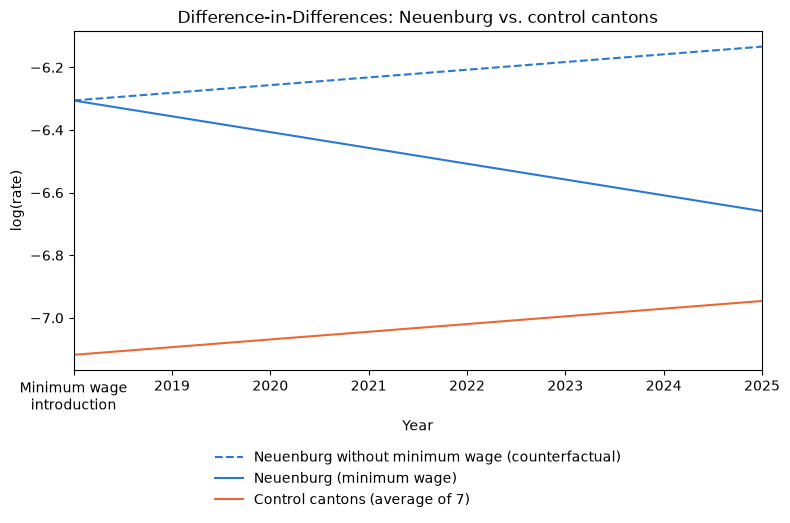

In [1]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# =============================================================
# 1. Einstellungen: Mindestlohn-Kanton, Kontrollkantone, Einführungsjahr
# =============================================================
MINDESTLOHN_KANTON = "Neuenburg"
KONTROLL_KANTONE   = ["Thurgau", "Wallis", "Bern", "Solothurn",
                      "St. Gallen", "Freiburg", "Aargau"]
EINFUEHRUNG        = 2018          # erstes volles Jahr mit Mindestlohn

# =============================================================
# 2. Daten laden und vorbereiten
# =============================================================
df = pd.read_csv("Crime_Pop_clean_copy2.csv")
d = df[df["Canton"].isin([MINDESTLOHN_KANTON] + KONTROLL_KANTONE)].copy()

d["log_rate"] = np.log(d["Number of Accused Persons"] / d["Resident Population"])
d["Treat"] = (d["Canton"] == MINDESTLOHN_KANTON).astype(int)   # 1 = Mindestlohn-Kanton, 0 = alle Kontrollkantone
d["After"] = (d["Year"] >= EINFUEHRUNG).astype(int)            # 1 = nach Einführung

# =============================================================
# 3. Regressionen (Standardfehler nach Kanton geclustert)
# =============================================================
cluster = {"cov_type": "cluster", "cov_kwds": {"groups": d["Canton"]}}

# Variante A: klassische DiD
mA = smf.ols("log_rate ~ Treat + After + Treat:After", data=d).fit(**cluster)
# Variante B: mit Kantons- und Jahres-Fixed-Effects
mB = smf.ols("log_rate ~ Treat:After + C(Canton) + C(Year)", data=d).fit(**cluster)

# =============================================================
# 4. Ergebnisse
# =============================================================
ergebnis = pd.DataFrame({
    "Modell": ["A: klassisch", "B: Kantons- + Jahres-FE"],
    "β3 (DiD)": [mA.params["Treat:After"], mB.params["Treat:After"]],
    "Std.-Fehler": [mA.bse["Treat:After"], mB.bse["Treat:After"]],
    "p-Wert": [mA.pvalues["Treat:After"], mB.pvalues["Treat:After"]],
    "R²": [mA.rsquared, mB.rsquared],
})
ergebnis["Effekt in %"] = (np.exp(ergebnis["β3 (DiD)"]) - 1) * 100

print(f"DiD: {MINDESTLOHN_KANTON} vs. {len(KONTROLL_KANTONE)} Kontrollkantone (Einführung {EINFUEHRUNG})\n")
print(ergebnis.round({"β3 (DiD)": 3, "Std.-Fehler": 3, "p-Wert": 5, "R²": 3, "Effekt in %": 1})
      .to_string(index=False))

# =============================================================
# 5. Grafik
# =============================================================
b0, b1, b2, b3 = mA.params[["Intercept", "Treat", "After", "Treat:After"]]

jahre = list(range(EINFUEHRUNG, d["Year"].max() + 1))
x = [jahre[0], jahre[-1]]

treat      = [b0 + b1, b0 + b1 + b2 + b3]   # Mindestlohn-Kanton
kontrolle  = [b0,      b0 + b2]             # Kontrollkantone (Durchschnitt)
kontrafakt = [b0 + b1, b0 + b1 + b2]        # Mindestlohn-Kanton ohne Mindestlohn

plt.figure(figsize=(8, 5.5))
plt.plot(x, kontrafakt, color="#2a78d6", linestyle="--",
         label=f"{MINDESTLOHN_KANTON} without minimum wage (counterfactual)")
plt.plot(x, treat, color="#2a78d6", label=f"{MINDESTLOHN_KANTON} (minimum wage)")
plt.plot(x, kontrolle, color="#eb6834", label=f"Control cantons (average of {len(KONTROLL_KANTONE)})")

beschriftung = ["Minimum wage\nintroduction"] + [str(j) for j in jahre[1:]]
plt.xticks(jahre, beschriftung)
plt.xlim(jahre[0], jahre[-1])
plt.xlabel("Year")
plt.ylabel("log(rate)")
plt.title(f"Difference-in-Differences: {MINDESTLOHN_KANTON} vs. control cantons")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt

DiD: Genf vs. 7 Kontrollkantone (Einführung 2021)

                 Modell  β3 (DiD)  Std.-Fehler  p-Wert    R²  Effekt in %
           A: klassisch     -0.17        0.151 0.25953 0.187        -15.6
B: Kantons- + Jahres-FE     -0.17        0.164 0.30180 0.868        -15.6


<module 'matplotlib.pyplot' from '/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/matplotlib/pyplot.py'>

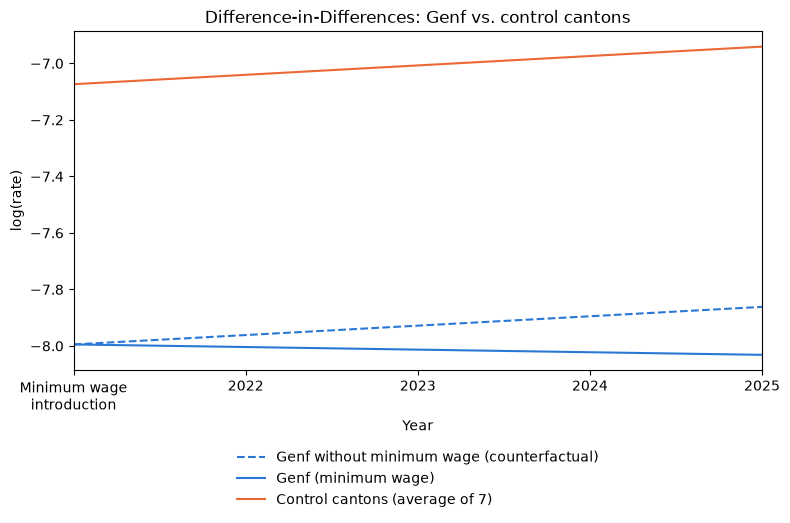

In [2]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# =============================================================
# 1. Einstellungen: Mindestlohn-Kanton, Kontrollkantone, Einführungsjahr
# =============================================================
MINDESTLOHN_KANTON = "Genf"
KONTROLL_KANTONE   = ["Thurgau", "Wallis", "Bern", "Solothurn",
                      "St. Gallen", "Freiburg", "Aargau"]
EINFUEHRUNG        = 2021          # erstes volles Jahr mit Mindestlohn

# =============================================================
# 2. Daten laden und vorbereiten
# =============================================================
df = pd.read_csv("Crime_Pop_clean_copy2.csv")
d = df[df["Canton"].isin([MINDESTLOHN_KANTON] + KONTROLL_KANTONE)].copy()

d["log_rate"] = np.log(d["Number of Accused Persons"] / d["Resident Population"])
d["Treat"] = (d["Canton"] == MINDESTLOHN_KANTON).astype(int)   # 1 = Mindestlohn-Kanton, 0 = alle Kontrollkantone
d["After"] = (d["Year"] >= EINFUEHRUNG).astype(int)            # 1 = nach Einführung

# =============================================================
# 3. Regressionen (Standardfehler nach Kanton geclustert)
# =============================================================
cluster = {"cov_type": "cluster", "cov_kwds": {"groups": d["Canton"]}}

# Variante A: klassische DiD
mA = smf.ols("log_rate ~ Treat + After + Treat:After", data=d).fit(**cluster)
# Variante B: mit Kantons- und Jahres-Fixed-Effects
mB = smf.ols("log_rate ~ Treat:After + C(Canton) + C(Year)", data=d).fit(**cluster)

# =============================================================
# 4. Ergebnisse
# =============================================================
ergebnis = pd.DataFrame({
    "Modell": ["A: klassisch", "B: Kantons- + Jahres-FE"],
    "β3 (DiD)": [mA.params["Treat:After"], mB.params["Treat:After"]],
    "Std.-Fehler": [mA.bse["Treat:After"], mB.bse["Treat:After"]],
    "p-Wert": [mA.pvalues["Treat:After"], mB.pvalues["Treat:After"]],
    "R²": [mA.rsquared, mB.rsquared],
})
ergebnis["Effekt in %"] = (np.exp(ergebnis["β3 (DiD)"]) - 1) * 100

print(f"DiD: {MINDESTLOHN_KANTON} vs. {len(KONTROLL_KANTONE)} Kontrollkantone (Einführung {EINFUEHRUNG})\n")
print(ergebnis.round({"β3 (DiD)": 3, "Std.-Fehler": 3, "p-Wert": 5, "R²": 3, "Effekt in %": 1})
      .to_string(index=False))

# =============================================================
# 5. Grafik
# =============================================================
b0, b1, b2, b3 = mA.params[["Intercept", "Treat", "After", "Treat:After"]]

jahre = list(range(EINFUEHRUNG, d["Year"].max() + 1))
x = [jahre[0], jahre[-1]]

treat      = [b0 + b1, b0 + b1 + b2 + b3]   # Mindestlohn-Kanton
kontrolle  = [b0,      b0 + b2]             # Kontrollkantone (Durchschnitt)
kontrafakt = [b0 + b1, b0 + b1 + b2]        # Mindestlohn-Kanton ohne Mindestlohn

plt.figure(figsize=(8, 5.5))
plt.plot(x, kontrafakt, color="#2a78d6", linestyle="--",
         label=f"{MINDESTLOHN_KANTON} without minimum wage (counterfactual)")
plt.plot(x, treat, color="#2a78d6", label=f"{MINDESTLOHN_KANTON} (minimum wage)")
plt.plot(x, kontrolle, color="#eb6834", label=f"Control cantons (average of {len(KONTROLL_KANTONE)})")

beschriftung = ["Minimum wage\nintroduction"] + [str(j) for j in jahre[1:]]
plt.xticks(jahre, beschriftung)
plt.xlim(jahre[0], jahre[-1])
plt.xlabel("Year")
plt.ylabel("log(rate)")
plt.title(f"Difference-in-Differences: {MINDESTLOHN_KANTON} vs. control cantons")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt

DiD: Basel-Stadt vs. 7 Kontrollkantone (Einführung 2023)

                 Modell  β3 (DiD)  Std.-Fehler  p-Wert    R²  Effekt in %
           A: klassisch    -0.446        0.149 0.00275 0.225        -36.0
B: Kantons- + Jahres-FE    -0.446        0.163 0.00611 0.886        -36.0


<module 'matplotlib.pyplot' from '/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/matplotlib/pyplot.py'>

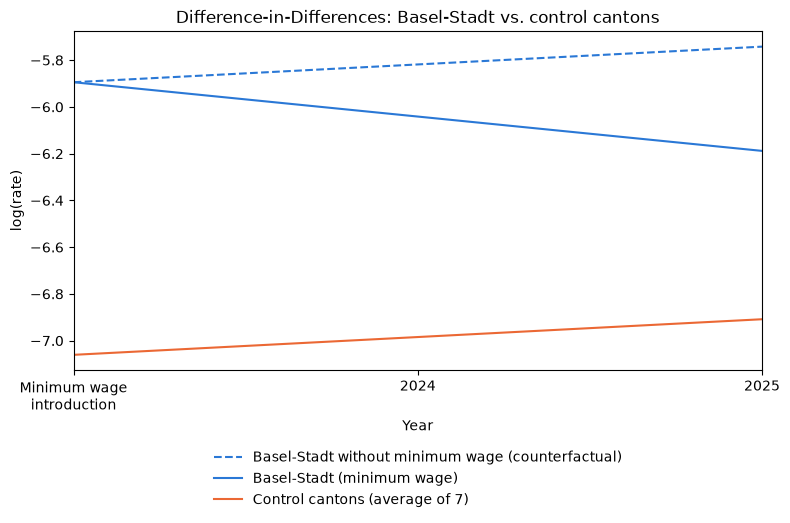

In [3]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# =============================================================
# 1. Einstellungen: Mindestlohn-Kanton, Kontrollkantone, Einführungsjahr
# =============================================================
MINDESTLOHN_KANTON = "Basel-Stadt"
KONTROLL_KANTONE   = ["Thurgau", "Wallis", "Bern", "Solothurn",
                      "St. Gallen", "Freiburg", "Aargau"]
EINFUEHRUNG        = 2023         # erstes volles Jahr mit Mindestlohn

# =============================================================
# 2. Daten laden und vorbereiten
# =============================================================
df = pd.read_csv("Crime_Pop_clean_copy2.csv")
d = df[df["Canton"].isin([MINDESTLOHN_KANTON] + KONTROLL_KANTONE)].copy()

d["log_rate"] = np.log(d["Number of Accused Persons"] / d["Resident Population"])
d["Treat"] = (d["Canton"] == MINDESTLOHN_KANTON).astype(int)   # 1 = Mindestlohn-Kanton, 0 = alle Kontrollkantone
d["After"] = (d["Year"] >= EINFUEHRUNG).astype(int)            # 1 = nach Einführung

# =============================================================
# 3. Regressionen (Standardfehler nach Kanton geclustert)
# =============================================================
cluster = {"cov_type": "cluster", "cov_kwds": {"groups": d["Canton"]}}

# Variante A: klassische DiD
mA = smf.ols("log_rate ~ Treat + After + Treat:After", data=d).fit(**cluster)
# Variante B: mit Kantons- und Jahres-Fixed-Effects
mB = smf.ols("log_rate ~ Treat:After + C(Canton) + C(Year)", data=d).fit(**cluster)

# =============================================================
# 4. Ergebnisse
# =============================================================
ergebnis = pd.DataFrame({
    "Modell": ["A: klassisch", "B: Kantons- + Jahres-FE"],
    "β3 (DiD)": [mA.params["Treat:After"], mB.params["Treat:After"]],
    "Std.-Fehler": [mA.bse["Treat:After"], mB.bse["Treat:After"]],
    "p-Wert": [mA.pvalues["Treat:After"], mB.pvalues["Treat:After"]],
    "R²": [mA.rsquared, mB.rsquared],
})
ergebnis["Effekt in %"] = (np.exp(ergebnis["β3 (DiD)"]) - 1) * 100

print(f"DiD: {MINDESTLOHN_KANTON} vs. {len(KONTROLL_KANTONE)} Kontrollkantone (Einführung {EINFUEHRUNG})\n")
print(ergebnis.round({"β3 (DiD)": 3, "Std.-Fehler": 3, "p-Wert": 5, "R²": 3, "Effekt in %": 1})
      .to_string(index=False))

# =============================================================
# 5. Grafik
# =============================================================
b0, b1, b2, b3 = mA.params[["Intercept", "Treat", "After", "Treat:After"]]

jahre = list(range(EINFUEHRUNG, d["Year"].max() + 1))
x = [jahre[0], jahre[-1]]

treat      = [b0 + b1, b0 + b1 + b2 + b3]   # Mindestlohn-Kanton
kontrolle  = [b0,      b0 + b2]             # Kontrollkantone (Durchschnitt)
kontrafakt = [b0 + b1, b0 + b1 + b2]        # Mindestlohn-Kanton ohne Mindestlohn

plt.figure(figsize=(8, 5.5))
plt.plot(x, kontrafakt, color="#2a78d6", linestyle="--",
         label=f"{MINDESTLOHN_KANTON} without minimum wage (counterfactual)")
plt.plot(x, treat, color="#2a78d6", label=f"{MINDESTLOHN_KANTON} (minimum wage)")
plt.plot(x, kontrolle, color="#eb6834", label=f"Control cantons (average of {len(KONTROLL_KANTONE)})")

beschriftung = ["Minimum wage\nintroduction"] + [str(j) for j in jahre[1:]]
plt.xticks(jahre, beschriftung)
plt.xlim(jahre[0], jahre[-1])
plt.xlabel("Year")
plt.ylabel("log(rate)")
plt.title(f"Difference-in-Differences: {MINDESTLOHN_KANTON} vs. control cantons")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt